<a href="https://colab.research.google.com/github/krithi-ks/PetroVision/blob/main/notebooks/computer-vision/PetroVision_CV_Inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/krithi-ks/PetroVision.git /content/PetroVision
%cd /content/PetroVision

from pathlib import Path

print("Project root:", Path.cwd())
print("\nProject files:")
for item in sorted(Path(".").iterdir()):
    print(" -", item.name)

Cloning into '/content/PetroVision'...
remote: Enumerating objects: 386, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 386 (delta 1), reused 0 (delta 0), pack-reused 384 (from 1)
Receiving objects: 100% (386/386), 151.60 MiB | 30.10 MiB/s, done.
Resolving deltas: 100% (119/119), done.
Updating files: 100% (136/136), done.
/content/PetroVision
Project root: /content/PetroVision

Project files:
 - .git
 - .gitignore
 - README.md
 - app
 - data
 - docs
 - models
 - notebooks
 - references
 - reports
 - requirements.txt
 - results
 - src


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
PROJECT_DIR = Path("/content/PetroVision")

In [ ]:
from pathlib import Path
import zipfile

ZIP_PATH = Path(
    "/content/drive/MyDrive/PetroVision/datasets/"
    "PetroVision.v1i.png-mask-semantic.zip"
)

EXTRACT_DIR = Path("/content/PetroVision/data/lados")

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"Dataset ZIP not found: {ZIP_PATH}")

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted to:", EXTRACT_DIR)


Dataset extracted to: /content/PetroVision/data/lados


## Load the trained DeepLabV3+ model

In [ ]:
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 10.6 MB/s eta 0:00:00


In [ ]:
import os
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type != "cuda":
    raise RuntimeError("GPU is required for this inference test.")

# Paths
CHECKPOINT = "/content/drive/MyDrive/PetroVision/models/cv_deeplab_001_best.pt"

# Create the same DeepLabV3+ architecture used during training
model = smp.DeepLabV3Plus(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    activation=None
).to(device)

# Load trained weights
checkpoint = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=False
)

if "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

print("DeepLabV3+ loaded successfully.")
print("Parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
DeepLabV3+ loaded successfully.
Parameters: 26677585


Image: 05_73_jpg.rf.52389c9f8d855d8030805280d1e8dc42.jpg
Original size: (640, 640)


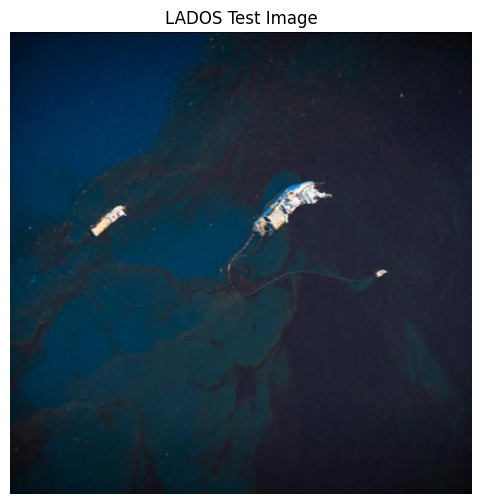

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

TEST_DIR = Path("/content/PetroVision/data/lados/test")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_images = sorted([
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in image_extensions
    and not p.name.endswith("_mask.png")
])

if not test_images:
    raise FileNotFoundError("No test images found.")

image_path = test_images[0]
image = Image.open(image_path).convert("RGB")

print("Image:", image_path.name)
print("Original size:", image.size)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("LADOS Test Image")
plt.show()

## Run DeepLabV3+ inference

In [ ]:
import time
import numpy as np
import torch
import torch.nn.functional as F

# Convert image to NumPy
image_np = np.array(image)

# Preprocessing: same normalization used during training
image_tensor = torch.from_numpy(
    image_np.astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

# Resize to the model input size
image_tensor = F.interpolate(
    image_tensor,
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

# Inference
with torch.no_grad():
    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    logits = model(image_tensor)

    if device.type == "cuda":
        torch.cuda.synchronize()

    inference_time = time.perf_counter() - start_time

# Convert logits → probability
probability = torch.sigmoid(logits)

# Binary petroleum mask
prediction = (probability >= 0.5).float()

print("Inference completed.")
print(f"Inference time: {inference_time * 1000:.2f} ms")
print("Prediction shape:", prediction.shape)
print(
    "Predicted petroleum pixels:",
    int(prediction.sum().item())
)

Inference completed.
Inference time: 2158.36 ms
Prediction shape: torch.Size([1, 1, 256, 256])
Predicted petroleum pixels: 51815


## Create the predicted mask + overlay

In [ ]:
# Convert prediction back to NumPy
pred_mask = prediction.squeeze().cpu().numpy().astype(np.uint8)

# Resize mask back to original image size
original_width, original_height = image.size

pred_mask_original = np.array(
    Image.fromarray(pred_mask).resize(
        (original_width, original_height),
        resample=Image.Resampling.NEAREST
    )
)

# Calculate visible petroleum coverage
coverage_percent = (
    np.count_nonzero(pred_mask_original)
    / pred_mask_original.size
) * 100

print(f"Visible petroleum coverage: {coverage_percent:.2f}%")
print("Predicted mask size:", pred_mask_original.shape)

Visible petroleum coverage: 79.06%
Predicted mask size: (640, 640)


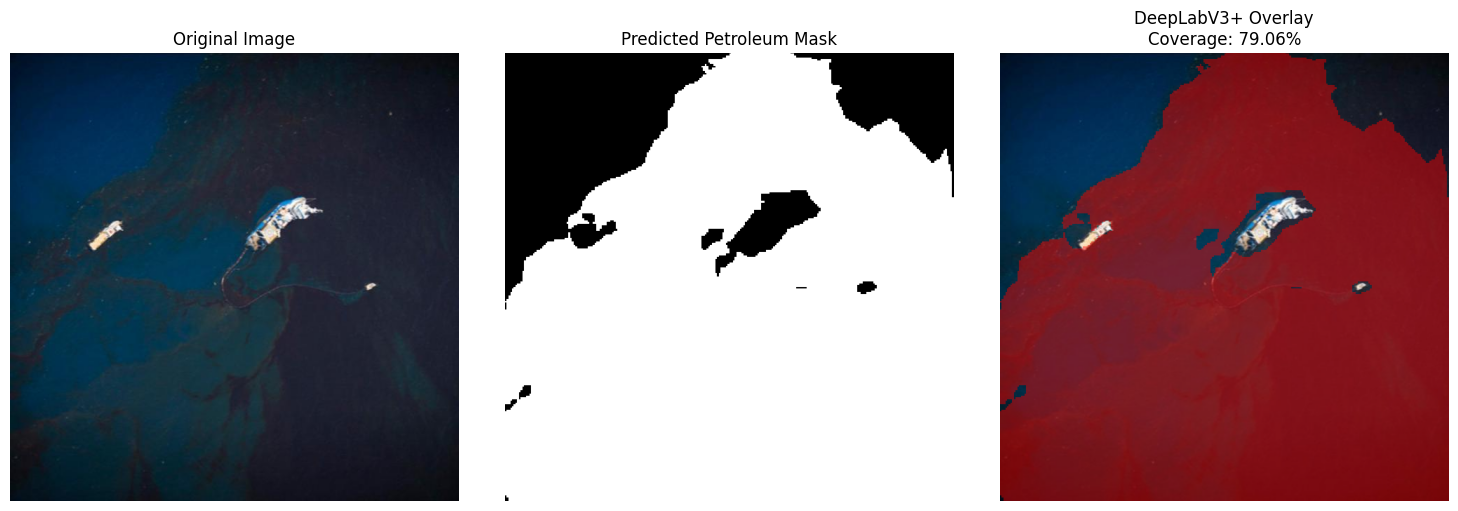

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 3, 2)
plt.imshow(pred_mask_original, cmap="gray")
plt.axis("off")
plt.title("Predicted Petroleum Mask")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.axis("off")
plt.title(f"DeepLabV3+ Overlay\nCoverage: {coverage_percent:.2f}%")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import json
import time
from PIL import Image

# Output directory
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/PetroVision/results/cv_inference"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save predicted mask
mask_path = OUTPUT_DIR / f"{image_path.stem}_predicted_mask.png"
Image.fromarray(
    (pred_mask_original * 255).astype(np.uint8)
).save(mask_path)

# Save overlay
overlay_path = OUTPUT_DIR / f"{image_path.stem}_overlay.png"
Image.fromarray(overlay).save(overlay_path)

# Save inference information
inference_record = {
    "model": "DeepLabV3+",
    "experiment_id": "CV-DEEPLAB-001",
    "image": image_path.name,
    "input_size": list(image.size),
    "model_input_size": [256, 256],
    "threshold": 0.5,
    "visible_petroleum_coverage_percent": float(coverage_percent),
    "inference_time_ms": float(inference_time * 1000),
    "predicted_mask": str(mask_path),
    "overlay": str(overlay_path),
    "note": (
        "Coverage represents predicted visible petroleum area "
        "in image space; it is not physical concentration, "
        "thickness, or volume."
    )
}

json_path = OUTPUT_DIR / f"{image_path.stem}_inference.json"

with open(json_path, "w") as f:
    json.dump(inference_record, f, indent=2)

print("Saved successfully.")
print("Mask:", mask_path)
print("Overlay:", overlay_path)
print("Record:", json_path)

Saved successfully.
Mask: /content/drive/MyDrive/PetroVision/results/cv_inference/05_73_jpg.rf.52389c9f8d855d8030805280d1e8dc42_predicted_mask.png
Overlay: /content/drive/MyDrive/PetroVision/results/cv_inference/05_73_jpg.rf.52389c9f8d855d8030805280d1e8dc42_overlay.png
Record: /content/drive/MyDrive/PetroVision/results/cv_inference/05_73_jpg.rf.52389c9f8d855d8030805280d1e8dc42_inference.json


In [ ]:
# Load the corresponding LADOS ground-truth mask
gt_path = image_path.with_name(
    image_path.stem + "_mask.png"
)

gt_mask_raw = np.array(Image.open(gt_path))

# LADOS petroleum classes:
# 1 = Emulsion, 2 = Oil, 4 = Sheen
gt_mask = np.isin(gt_mask_raw, [1, 2, 4]).astype(np.uint8)

# Convert to boolean
gt_bool = gt_mask.astype(bool)
pred_bool = pred_mask_original.astype(bool)

# Pixel counts
tp = np.logical_and(gt_bool, pred_bool).sum()
fp = np.logical_and(~gt_bool, pred_bool).sum()
fn = np.logical_and(gt_bool, ~pred_bool).sum()
tn = np.logical_and(~gt_bool, ~pred_bool).sum()

# Metrics
iou = tp / (tp + fp + fn) if (tp + fp + fn) else 1.0

dice = (
    2 * tp / (2 * tp + fp + fn)
    if (2 * tp + fp + fn)
    else 1.0
)

precision = (
    tp / (tp + fp)
    if (tp + fp)
    else 0.0
)

recall = (
    tp / (tp + fn)
    if (tp + fn)
    else 0.0
)

accuracy = (tp + tn) / (tp + tn + fp + fn)

gt_coverage = gt_bool.mean() * 100

print("----- Single Image Ground-Truth Evaluation -----")
print(f"Ground-truth coverage: {gt_coverage:.2f}%")
print(f"Predicted coverage:    {coverage_percent:.2f}%")
print()
print(f"IoU:        {iou:.4f}")
print(f"Dice:       {dice:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"Accuracy:   {accuracy:.4f}")
print()
print(f"TP: {tp:,}")
print(f"FP: {fp:,}")
print(f"FN: {fn:,}")
print(f"TN: {tn:,}")

----- Single Image Ground-Truth Evaluation -----
Ground-truth coverage: 75.31%
Predicted coverage:    79.06%

IoU:        0.7972
Dice:       0.8872
Precision:  0.8661
Recall:     0.9092
Accuracy:   0.8258

TP: 280,477
FP: 43,353
FN: 28,003
TN: 57,767


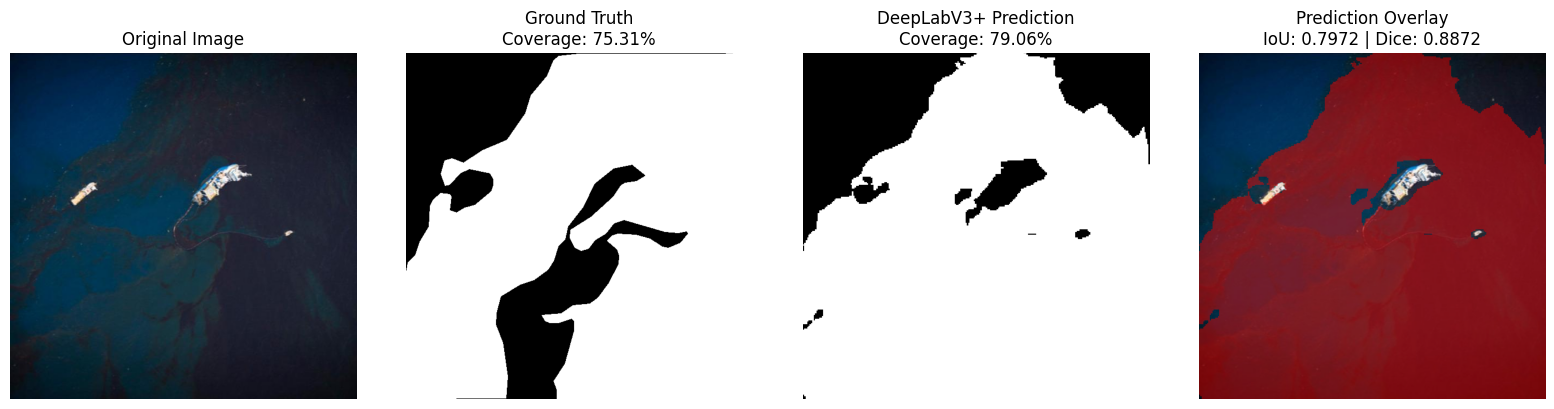

In [ ]:
plt.figure(figsize=(16, 4))

# 1. Original
plt.subplot(1, 4, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

# 2. Ground Truth
plt.subplot(1, 4, 2)
plt.imshow(gt_mask, cmap="gray")
plt.axis("off")
plt.title(f"Ground Truth\nCoverage: {gt_coverage:.2f}%")

# 3. Prediction
plt.subplot(1, 4, 3)
plt.imshow(pred_mask_original, cmap="gray")
plt.axis("off")
plt.title(f"DeepLabV3+ Prediction\nCoverage: {coverage_percent:.2f}%")

# 4. Overlay
plt.subplot(1, 4, 4)
plt.imshow(overlay)
plt.axis("off")
plt.title(
    f"Prediction Overlay\n"
    f"IoU: {iou:.4f} | Dice: {dice:.4f}"
)

plt.tight_layout()
plt.show()

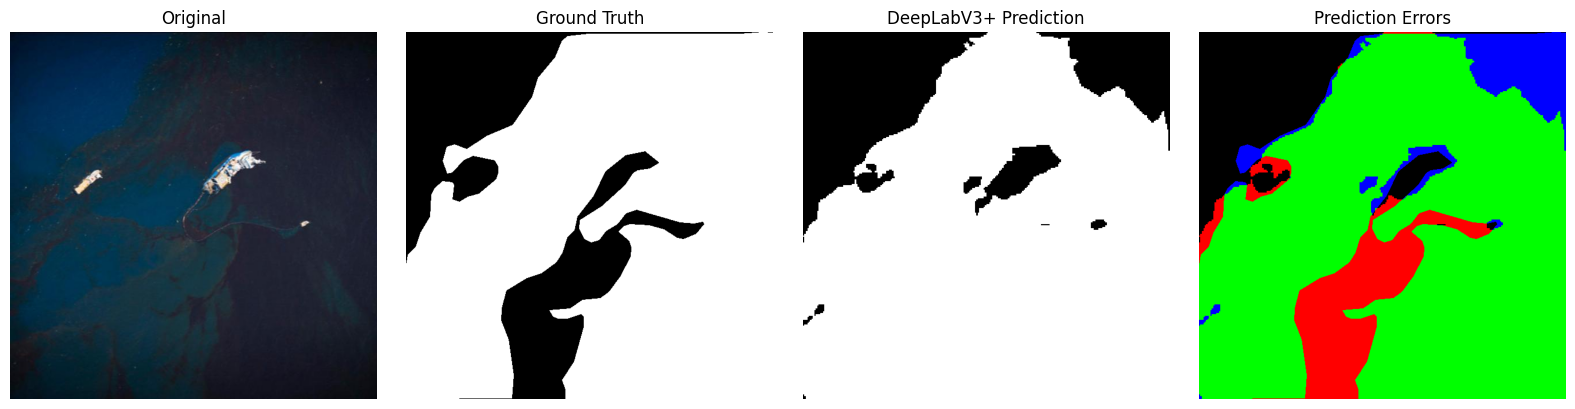

In [ ]:
# Create error map
error_map = np.zeros(
    (*gt_bool.shape, 3),
    dtype=np.uint8
)

# True Positive
tp_mask = gt_bool & pred_bool

# False Positive
fp_mask = ~gt_bool & pred_bool

# False Negative
fn_mask = gt_bool & ~pred_bool

# True Positive
error_map[tp_mask] = [0, 255, 0]

# False Positive
error_map[fp_mask] = [255, 0, 0]

# False Negative
error_map[fn_mask] = [0, 0, 255]

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original")

plt.subplot(1, 4, 2)
plt.imshow(gt_mask, cmap="gray")
plt.axis("off")
plt.title("Ground Truth")

plt.subplot(1, 4, 3)
plt.imshow(pred_mask_original, cmap="gray")
plt.axis("off")
plt.title("DeepLabV3+ Prediction")

plt.subplot(1, 4, 4)
plt.imshow(error_map)
plt.axis("off")
plt.title("Prediction Errors")

plt.tight_layout()
plt.show()

Green → True Positive

Red   → False Positive

Blue  → False Negative

Black → True Negative

In [ ]:
import pandas as pd

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

prob_original = F.interpolate(
    probability,
    size=(original_height, original_width),
    mode="bilinear",
    align_corners=False
).squeeze().cpu().numpy()

for threshold in thresholds:

    pred = (prob_original >= threshold)

    tp = np.logical_and(gt_bool, pred).sum()
    fp = np.logical_and(~gt_bool, pred).sum()
    fn = np.logical_and(gt_bool, ~pred).sum()

    iou_t = tp / (tp + fp + fn) if (tp + fp + fn) else 1.0
    dice_t = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 1.0

    results.append({
        "Threshold": threshold,
        "IoU": iou_t,
        "Dice": dice_t
    })

threshold_df = pd.DataFrame(results)
threshold_df

,Threshold,IoU,Dice
0,0.3,0.831973,0.908281
1,0.4,0.813752,0.897314
2,0.5,0.797598,0.887404
3,0.6,0.772209,0.871465
4,0.7,0.736078,0.847978


In [ ]:
import json
import numpy as np
import torch
from torch.utils.data import DataLoader
from src.vision.lados_dataset import LADOSDataset

# Test dataset — no augmentation
test_dataset = LADOSDataset(
    root_dir="/content/PetroVision/data/lados",
    split="test",
    image_size=256,
    augment=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

# Accumulate confusion counts for every threshold
results = {
    threshold: {"TP": 0, "FP": 0, "FN": 0, "TN": 0}
    for threshold in thresholds
}

model.eval()

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        for threshold in thresholds:

            predictions = probabilities >= threshold
            ground_truth = masks >= 0.5

            results[threshold]["TP"] += torch.logical_and(
                predictions, ground_truth
            ).sum().item()

            results[threshold]["FP"] += torch.logical_and(
                predictions, ~ground_truth
            ).sum().item()

            results[threshold]["FN"] += torch.logical_and(
                ~predictions, ground_truth
            ).sum().item()

            results[threshold]["TN"] += torch.logical_and(
                ~predictions, ~ground_truth
            ).sum().item()


# Calculate metrics
threshold_results = []

for threshold in thresholds:

    counts = results[threshold]

    tp = counts["TP"]
    fp = counts["FP"]
    fn = counts["FN"]
    tn = counts["TN"]

    iou = tp / (tp + fp + fn) if (tp + fp + fn) else 1.0
    dice = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn)
        else 1.0
    )
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    threshold_results.append({
        "threshold": threshold,
        "IoU": iou,
        "Dice": dice,
        "Precision": precision,
        "Recall": recall,
        "Accuracy": accuracy,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })


threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,threshold,IoU,Dice,Precision,Recall,Accuracy,TP,FP,FN,TN
0,0.3,0.814984,0.898062,0.865426,0.933255,0.887192,11170039,1736937,798864,8773008
1,0.4,0.818813,0.900382,0.879955,0.921778,0.891395,11032676,1505090,936227,9004855
2,0.5,0.820109,0.901165,0.894639,0.907787,0.893977,10865215,1279592,1103688,9230353
3,0.6,0.817325,0.899482,0.908308,0.890825,0.893988,10662198,1076328,1306705,9433617
4,0.7,0.809053,0.894449,0.921226,0.869185,0.890773,10403189,889578,1565714,9620367


## Load SegFormer checkpoint

In [ ]:
from transformers import SegformerForSemanticSegmentation
import torch

SEGFORMER_CHECKPOINT = (
    "/content/drive/MyDrive/PetroVision/"
    "models/cv_segformer_001_best.pt"
)

segformer = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b0",
    num_labels=1,
    ignore_mismatched_sizes=True
).to(device)

checkpoint = torch.load(
    SEGFORMER_CHECKPOINT,
    map_location=device,
    weights_only=False
)

segformer.load_state_dict(
    checkpoint["model_state_dict"]
)

segformer.eval()

print("SegFormer-B0 loaded successfully.")
print(
    "Parameters:",
    sum(p.numel() for p in segformer.parameters())
)

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.running_var                      

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

SegFormer-B0 loaded successfully.
Parameters: 3714401


In [ ]:
id="segformer_inference"
import time
import torch
import torch.nn.functional as F
import numpy as np

image_np = np.array(image)

image_tensor = torch.from_numpy(
    image_np.astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

image_tensor = F.interpolate(
    image_tensor,
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

with torch.no_grad():
    torch.cuda.synchronize()
    start_time = time.perf_counter()

    outputs = segformer(
        pixel_values=image_tensor
    )

    torch.cuda.synchronize()
    inference_time = time.perf_counter() - start_time

# SegFormer output is lower resolution
logits = outputs.logits

logits = F.interpolate(
    logits,
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

probability = torch.sigmoid(logits)

prediction = (
    probability >= 0.5
).float()

print("SegFormer inference completed.")
print(f"Inference time: {inference_time * 1000:.2f} ms")
print("Prediction shape:", prediction.shape)

SegFormer inference completed.
Inference time: 397.10 ms
Prediction shape: torch.Size([1, 1, 256, 256])


In [ ]:
pred_mask = prediction.squeeze().cpu().numpy().astype(np.uint8)

original_width, original_height = image.size

pred_mask_original = np.array(
    Image.fromarray(pred_mask).resize(
        (original_width, original_height),
        resample=Image.Resampling.NEAREST
    )
)

coverage_percent = (
    np.count_nonzero(pred_mask_original)
    / pred_mask_original.size
) * 100

print(f"SegFormer visible petroleum coverage: {coverage_percent:.2f}%")
print("Predicted mask size:", pred_mask_original.shape)

SegFormer visible petroleum coverage: 32.11%
Predicted mask size: (640, 640)


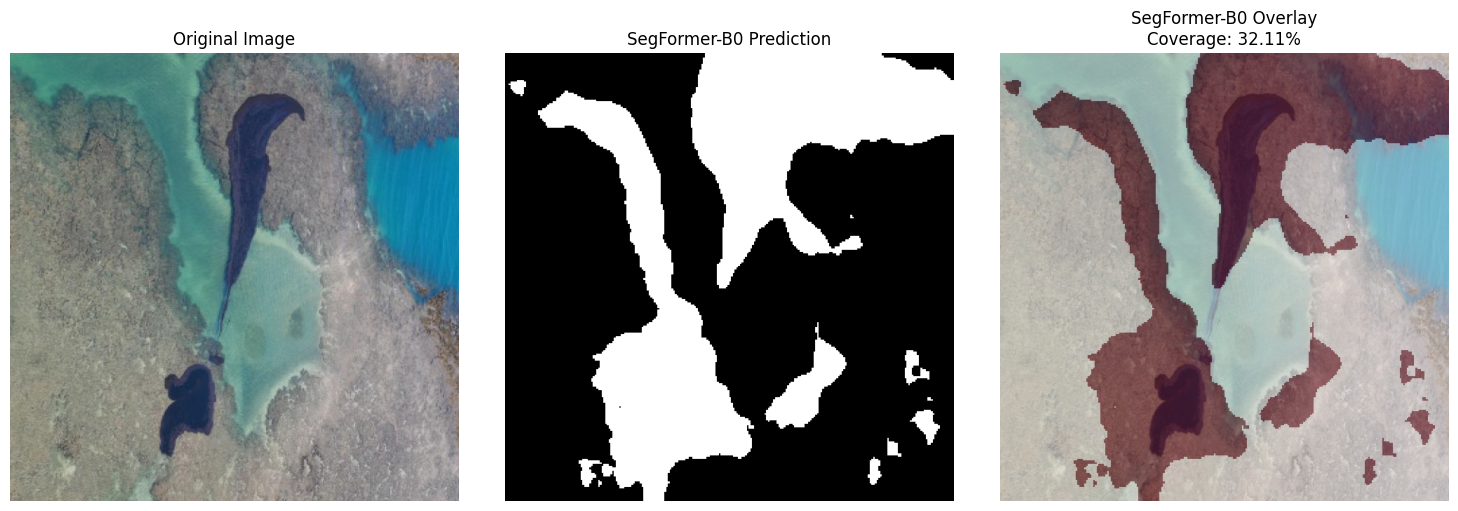

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 3, 2)
plt.imshow(pred_mask_original, cmap="gray")
plt.axis("off")
plt.title("SegFormer-B0 Prediction")

plt.subplot(1, 3, 3)
plt.imshow(image_np)
plt.imshow(
    pred_mask_original,
    cmap="Reds",
    alpha=0.45
)
plt.axis("off")
plt.title(
    f"SegFormer-B0 Overlay\n"
    f"Coverage: {coverage_percent:.2f}%"
)

plt.tight_layout()
plt.show()

In [ ]:
# Ground truth for the same image
gt_path = image_path.with_name(
    image_path.stem + "_mask.png"
)

gt_raw = np.array(Image.open(gt_path))

# LADOS petroleum classes: Emulsion(1), Oil(2), Sheen(4)
gt_mask = np.isin(
    gt_raw, [1, 2, 4]
).astype(np.uint8)

gt_bool = gt_mask.astype(bool)
pred_bool = pred_mask_original.astype(bool)

# Confusion counts
tp = np.logical_and(gt_bool, pred_bool).sum()
fp = np.logical_and(~gt_bool, pred_bool).sum()
fn = np.logical_and(gt_bool, ~pred_bool).sum()
tn = np.logical_and(~gt_bool, ~pred_bool).sum()

# Metrics
iou = tp / (tp + fp + fn) if (tp + fp + fn) else 1.0
dice = (
    2 * tp / (2 * tp + fp + fn)
    if (2 * tp + fp + fn)
    else 1.0
)
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
accuracy = (tp + tn) / (tp + tn + fp + fn)

gt_coverage = gt_bool.mean() * 100

print(f"Ground-truth coverage: {gt_coverage:.2f}%")
print(f"Predicted coverage:     {coverage_percent:.2f}%")
print(f"IoU:                    {iou:.4f}")
print(f"Dice:                   {dice:.4f}")
print(f"Precision:              {precision:.4f}")
print(f"Recall:                 {recall:.4f}")
print(f"Accuracy:               {accuracy:.4f}")

Ground-truth coverage: 5.34%
Predicted coverage:     32.11%
IoU:                    0.1587
Dice:                   0.2739
Precision:              0.1597
Recall:                 0.9597
Accuracy:               0.7281


## Mask2Former

In [ ]:
from transformers import Mask2FormerForUniversalSegmentation
import torch

MASK2FORMER_CHECKPOINT = (
    "/content/drive/MyDrive/PetroVision/"
    "models/cv_mask2former_001_best.pt"
)

mask2former = Mask2FormerForUniversalSegmentation.from_pretrained(
    "facebook/mask2former-swin-small-ade-semantic",
    num_labels=2,
    ignore_mismatched_sizes=True
).to(device)

checkpoint = torch.load(
    MASK2FORMER_CHECKPOINT,
    map_location=device,
    weights_only=False
)

mask2former.load_state_dict(
    checkpoint["model_state_dict"]
)

mask2former.eval()

print("Mask2Former loaded successfully.")
print(
    "Parameters:",
    sum(p.numel() for p in mask2former.parameters())
)

config.json:   0%|          | 0.00/82.5k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-small-ade-semantic
Key                                                                                                                      | Status     |                                                                                         
-------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    |                                                                            

Mask2Former loaded successfully.
Parameters: 68721037


In [ ]:
import time
import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoImageProcessor

# Load the matching image processor
processor = AutoImageProcessor.from_pretrained(
    "facebook/mask2former-swin-small-ade-semantic"
)

image_tensor = torch.from_numpy(
    image_np.astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

image_tensor = F.interpolate(
    image_tensor,
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

with torch.no_grad():

    torch.cuda.synchronize()
    start_time = time.perf_counter()

    outputs = mask2former(
        pixel_values=image_tensor
    )

    torch.cuda.synchronize()
    inference_time = time.perf_counter() - start_time

# Post-process using the IMAGE PROCESSOR
semantic_map = processor.post_process_semantic_segmentation(
    outputs,
    target_sizes=[(256, 256)]
)[0]

semantic_map = semantic_map.cpu().numpy()

print("Mask2Former inference completed.")
print(f"Inference time: {inference_time * 1000:.2f} ms")
print("Prediction shape:", semantic_map.shape)
print("Predicted classes:", np.unique(semantic_map))

preprocessor_config.json:   0%|          | 0.00/538 [00:00<?, ?B/s]

Mask2Former inference completed.
Inference time: 122.31 ms
Prediction shape: (256, 256)
Predicted classes: [0 1]


In [ ]:
# Class 1 = petroleum
pred_mask = (
    semantic_map == 1
).astype(np.uint8)

pred_mask_original = np.array(
    Image.fromarray(pred_mask)
    .resize(
        image.size,
        resample=Image.Resampling.NEAREST
    )
)

coverage_percent = (
    np.count_nonzero(pred_mask_original)
    / pred_mask_original.size
) * 100

print(
    f"Mask2Former visible petroleum coverage: "
    f"{coverage_percent:.2f}%"
)

Mask2Former visible petroleum coverage: 85.04%


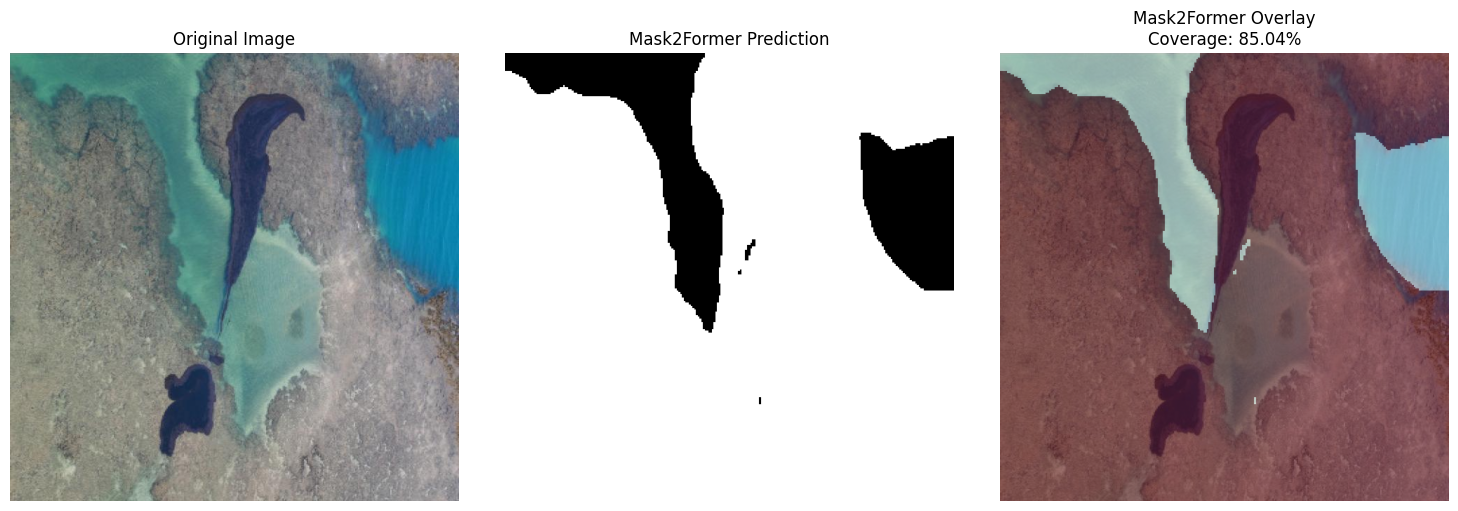

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 3, 2)
plt.imshow(pred_mask_original, cmap="gray")
plt.axis("off")
plt.title("Mask2Former Prediction")

plt.subplot(1, 3, 3)
plt.imshow(image_np)
plt.imshow(
    pred_mask_original,
    cmap="Reds",
    alpha=0.45
)
plt.axis("off")
plt.title(
    f"Mask2Former Overlay\n"
    f"Coverage: {coverage_percent:.2f}%"
)

plt.tight_layout()
plt.show()

In [ ]:
# Mask2Former single-image evaluation against LADOS ground truth

from sklearn.metrics import confusion_matrix

# Mask2Former class 1 = predicted petroleum
pred_mask = (semantic_map == 1).astype(np.uint8)

# Load LADOS ground-truth mask
gt_mask_path = image_path.with_name(
    image_path.stem + "_mask.png"
)

gt_mask = np.array(
    Image.open(gt_mask_path).convert("L")
)

# LADOS petroleum classes:
# 1 = Emulsion, 2 = Oil, 4 = Sheen
gt_petroleum = np.isin(
    gt_mask,
    [1, 2, 4]
).astype(np.uint8)

# Resize prediction to original image size
pred_mask_original = np.array(
    Image.fromarray(pred_mask)
    .resize(
        image.size,
        resample=Image.Resampling.NEAREST
    )
)

# Flatten
y_true = gt_petroleum.flatten()
y_pred = pred_mask_original.flatten()

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
).ravel()

iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0
dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
accuracy = (tp + tn) / (tp + tn + fp + fn)

gt_coverage = (
    np.count_nonzero(gt_petroleum)
    / gt_petroleum.size
) * 100

pred_coverage = (
    np.count_nonzero(pred_mask_original)
    / pred_mask_original.size
) * 100

print("Mask2Former Ground-Truth Evaluation")
print("------------------------------------")
print(f"Ground-truth coverage : {gt_coverage:.2f}%")
print(f"Predicted coverage    : {pred_coverage:.2f}%")
print(f"IoU                   : {iou:.4f}")
print(f"Dice                  : {dice:.4f}")
print(f"Precision             : {precision:.4f}")
print(f"Recall                : {recall:.4f}")
print(f"Accuracy              : {accuracy:.4f}")
print(f"TP: {tp:,}")
print(f"FP: {fp:,}")
print(f"FN: {fn:,}")
print(f"TN: {tn:,}")

Mask2Former Ground-Truth Evaluation
------------------------------------
Ground-truth coverage : 5.34%
Predicted coverage    : 85.04%
IoU                   : 0.0622
Dice                  : 0.1171
Precision             : 0.0622
Recall                : 0.9906
Accuracy              : 0.2020
TP: 21,680
FP: 326,652
FN: 206
TN: 61,062


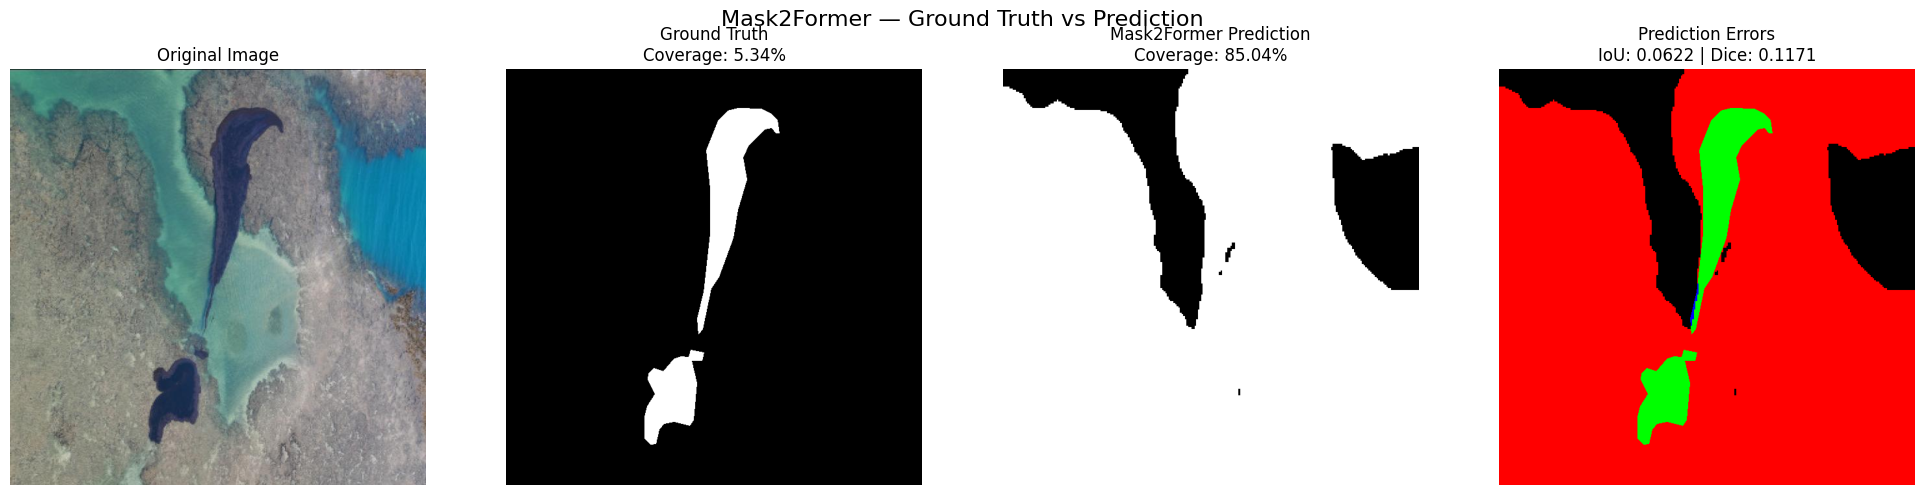

In [ ]:
# Mask2Former: Ground Truth vs Prediction vs Error Map

# Ground truth petroleum mask
gt_binary = np.isin(gt_mask, [1, 2, 4]).astype(np.uint8)

# Mask2Former prediction
pred_binary = pred_mask_original.astype(np.uint8)

# Error categories
tp = (gt_binary == 1) & (pred_binary == 1)
fp = (gt_binary == 0) & (pred_binary == 1)
fn = (gt_binary == 1) & (pred_binary == 0)

# Create RGB error map
error_map = np.zeros(
    (*gt_binary.shape, 3),
    dtype=np.uint8
)

# True Positive = Green
error_map[tp] = [0, 255, 0]

# False Positive = Red
error_map[fp] = [255, 0, 0]

# False Negative = Blue
error_map[fn] = [0, 0, 255]

plt.figure(figsize=(20, 5))

# Original
plt.subplot(1, 4, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

# Ground Truth
plt.subplot(1, 4, 2)
plt.imshow(gt_binary, cmap="gray")
plt.axis("off")
plt.title(f"Ground Truth\nCoverage: {gt_coverage:.2f}%")

# Prediction
plt.subplot(1, 4, 3)
plt.imshow(pred_binary, cmap="gray")
plt.axis("off")
plt.title(f"Mask2Former Prediction\nCoverage: {pred_coverage:.2f}%")

# Error map
plt.subplot(1, 4, 4)
plt.imshow(error_map)
plt.axis("off")
plt.title(
    f"Prediction Errors\n"
    f"IoU: {iou:.4f} | Dice: {dice:.4f}"
)

plt.suptitle(
    "Mask2Former — Ground Truth vs Prediction",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# Verify the ground-truth mask being used

from pathlib import Path
from PIL import Image
import numpy as np

print("Image:")
print(image_path)

gt_path = image_path.with_name(
    image_path.stem + "_mask.png"
)

print("\nGround-truth mask:")
print(gt_path)

if not gt_path.exists():
    raise FileNotFoundError(f"Ground-truth mask not found: {gt_path}")

verified_gt = np.array(
    Image.open(gt_path).convert("L")
)

print("\nImage size:", image.size)
print("GT mask size:", verified_gt.shape)
print("GT mask unique IDs:", np.unique(verified_gt))

verified_petroleum = np.isin(
    verified_gt,
    [1, 2, 4]
)

verified_coverage = (
    verified_petroleum.sum()
    / verified_petroleum.size
) * 100

print(f"\nVerified petroleum coverage: {verified_coverage:.2f}%")

Image:
/content/PetroVision/data/lados/test/1-s2-0-S0025326X20300795-ga1_jpg.rf.146acb49222beff322771e6a18d1c5ee.jpg

Ground-truth mask:
/content/PetroVision/data/lados/test/1-s2-0-S0025326X20300795-ga1_jpg.rf.146acb49222beff322771e6a18d1c5ee_mask.png

Image size: (640, 640)
GT mask size: (640, 640)
GT mask unique IDs: [0 2]

Verified petroleum coverage: 5.34%


## YOLO11n-Seg

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 6.6 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
import torch

DEVICE = 0

YOLO_CHECKPOINT = (
    "/content/drive/MyDrive/PetroVision/"
    "models/cv_yolo_001_best.pt"
)

yolo_model = YOLO(YOLO_CHECKPOINT)

print("YOLO11n-Seg loaded successfully.")
print("Device:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO11n-Seg loaded successfully.
Device: Tesla T4


In [ ]:
# YOLO11n-Seg inference on the current LADOS test image

import time

with torch.no_grad():
    torch.cuda.synchronize()
    start_time = time.perf_counter()

    yolo_results = yolo_model.predict(
        source=str(image_path),
        imgsz=640,
        device=DEVICE,
        verbose=False,
        retina_masks=True
    )

    torch.cuda.synchronize()
    yolo_inference_time = time.perf_counter() - start_time

result = yolo_results[0]

print("YOLO11n-Seg inference completed.")
print(f"Inference time: {yolo_inference_time * 1000:.2f} ms")

if result.masks is not None:
    print("Predicted instances:", len(result.masks.data))
else:
    print("Predicted instances: 0")

YOLO11n-Seg inference completed.
Inference time: 1208.70 ms
Predicted instances: 1


In [ ]:
# Convert YOLO instance mask(s) into one binary petroleum mask

if result.masks is not None:
    yolo_masks = result.masks.data

    # Combine all detected petroleum instances
    yolo_binary = torch.any(
        yolo_masks > 0.5,
        dim=0
    ).cpu().numpy().astype(np.uint8)

    # Resize to original image size
    yolo_mask_original = np.array(
        Image.fromarray(yolo_binary)
        .resize(
            image.size,
            resample=Image.Resampling.NEAREST
        )
    )

else:
    yolo_mask_original = np.zeros(
        (image.size[1], image.size[0]),
        dtype=np.uint8
    )

yolo_coverage = (
    np.count_nonzero(yolo_mask_original)
    / yolo_mask_original.size
) * 100

print(f"YOLO predicted coverage: {yolo_coverage:.2f}%")
print("Mask size:", yolo_mask_original.shape)

YOLO predicted coverage: 81.78%
Mask size: (640, 640)


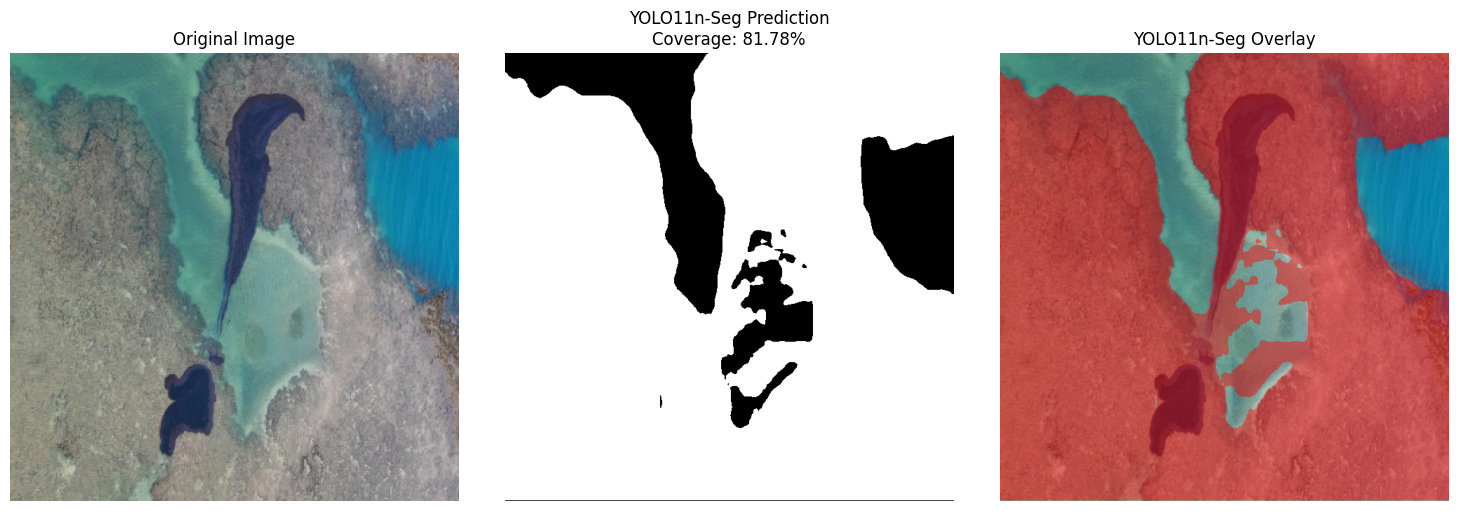

In [ ]:
# YOLO11n-Seg prediction visualization
# Original | Predicted Mask | Overlay

yolo_overlay = image_np.copy()

mask_region = yolo_mask_original.astype(bool)

yolo_overlay[mask_region] = (
    0.55 * yolo_overlay[mask_region]
    + 0.45 * np.array([255, 0, 0])
).astype(np.uint8)

plt.figure(figsize=(15, 5))

# Original
plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

# Prediction mask
plt.subplot(1, 3, 2)
plt.imshow(yolo_mask_original, cmap="gray")
plt.axis("off")
plt.title(
    f"YOLO11n-Seg Prediction\n"
    f"Coverage: {yolo_coverage:.2f}%"
)

# Overlay
plt.subplot(1, 3, 3)
plt.imshow(yolo_overlay)
plt.axis("off")
plt.title("YOLO11n-Seg Overlay")

plt.tight_layout()
plt.show()

In [ ]:
# YOLO11n-Seg: Ground Truth vs Prediction

gt_binary = np.isin(
    verified_gt,
    [1, 2, 4]
).astype(np.uint8)

pred_binary = yolo_mask_original.astype(np.uint8)

tp = ((gt_binary == 1) & (pred_binary == 1)).sum()
fp = ((gt_binary == 0) & (pred_binary == 1)).sum()
fn = ((gt_binary == 1) & (pred_binary == 0)).sum()
tn = ((gt_binary == 0) & (pred_binary == 0)).sum()

iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0
dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
accuracy = (tp + tn) / (tp + tn + fp + fn)

print("YOLO11n-Seg Ground-Truth Evaluation")
print("------------------------------------")
print(f"Ground-truth coverage : {gt_coverage:.2f}%")
print(f"Predicted coverage    : {yolo_coverage:.2f}%")
print(f"IoU                   : {iou:.4f}")
print(f"Dice                  : {dice:.4f}")
print(f"Precision             : {precision:.4f}")
print(f"Recall                : {recall:.4f}")
print(f"Accuracy              : {accuracy:.4f}")
print(f"TP: {tp:,}")
print(f"FP: {fp:,}")
print(f"FN: {fn:,}")
print(f"TN: {tn:,}")

YOLO11n-Seg Ground-Truth Evaluation
------------------------------------
Ground-truth coverage : 5.34%
Predicted coverage    : 81.78%
IoU                   : 0.0653
Dice                  : 0.1227
Precision             : 0.0653
Recall                : 1.0000
Accuracy              : 0.2357
TP: 21,886
FP: 313,072
FN: 0
TN: 74,642


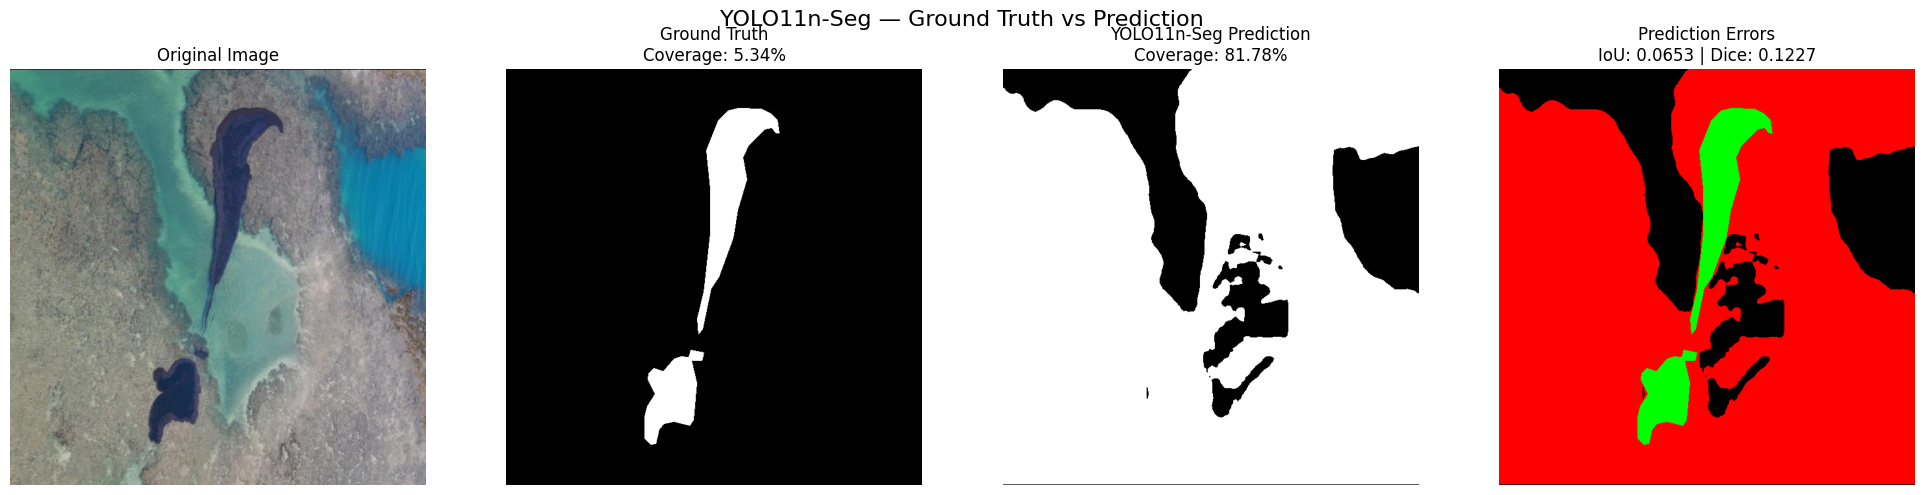

In [ ]:
# YOLO11n-Seg: Ground Truth vs Prediction vs Error Map

gt_binary = np.isin(
    verified_gt,
    [1, 2, 4]
).astype(np.uint8)

pred_binary = yolo_mask_original.astype(np.uint8)

# Error categories
tp_mask = (gt_binary == 1) & (pred_binary == 1)
fp_mask = (gt_binary == 0) & (pred_binary == 1)
fn_mask = (gt_binary == 1) & (pred_binary == 0)

# RGB error map
error_map = np.zeros(
    (*gt_binary.shape, 3),
    dtype=np.uint8
)

# Green = True Positive
error_map[tp_mask] = [0, 255, 0]

# Red = False Positive
error_map[fp_mask] = [255, 0, 0]

# Blue = False Negative
error_map[fn_mask] = [0, 0, 255]

plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 4, 2)
plt.imshow(gt_binary, cmap="gray")
plt.axis("off")
plt.title(f"Ground Truth\nCoverage: {gt_coverage:.2f}%")

plt.subplot(1, 4, 3)
plt.imshow(pred_binary, cmap="gray")
plt.axis("off")
plt.title(f"YOLO11n-Seg Prediction\nCoverage: {yolo_coverage:.2f}%")

plt.subplot(1, 4, 4)
plt.imshow(error_map)
plt.axis("off")
plt.title(
    f"Prediction Errors\n"
    f"IoU: {iou:.4f} | Dice: {dice:.4f}"
)

plt.suptitle(
    "YOLO11n-Seg — Ground Truth vs Prediction",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# DeepLabV3+ on the SAME image currently being evaluated

import time
import torch
import torch.nn.functional as F

# Prepare the current image
image_np = np.array(image)

image_tensor = torch.from_numpy(
    image_np.astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

image_tensor = F.interpolate(
    image_tensor,
    size=(256, 256),
    mode="bilinear",
    align_corners=False
)

with torch.no_grad():
    torch.cuda.synchronize()
    start_time = time.perf_counter()

    deeplab_logits = model(image_tensor)

    torch.cuda.synchronize()
    deeplab_time = time.perf_counter() - start_time

deeplab_probability = torch.sigmoid(deeplab_logits)

deeplab_prediction = (
    deeplab_probability >= 0.5
).float()

deeplab_mask = (
    deeplab_prediction.squeeze()
    .cpu()
    .numpy()
    .astype(np.uint8)
)

# Resize prediction back to original image size
deeplab_mask_original = np.array(
    Image.fromarray(deeplab_mask)
    .resize(
        image.size,
        resample=Image.Resampling.NEAREST
    )
)

deeplab_coverage = (
    np.count_nonzero(deeplab_mask_original)
    / deeplab_mask_original.size
) * 100

print("DeepLabV3+ inference completed.")
print(f"Inference time: {deeplab_time * 1000:.2f} ms")
print(f"Ground-truth coverage: {gt_coverage:.2f}%")
print(f"DeepLabV3+ coverage: {deeplab_coverage:.2f}%")

DeepLabV3+ inference completed.
Inference time: 18.07 ms
Ground-truth coverage: 5.34%
DeepLabV3+ coverage: 55.91%


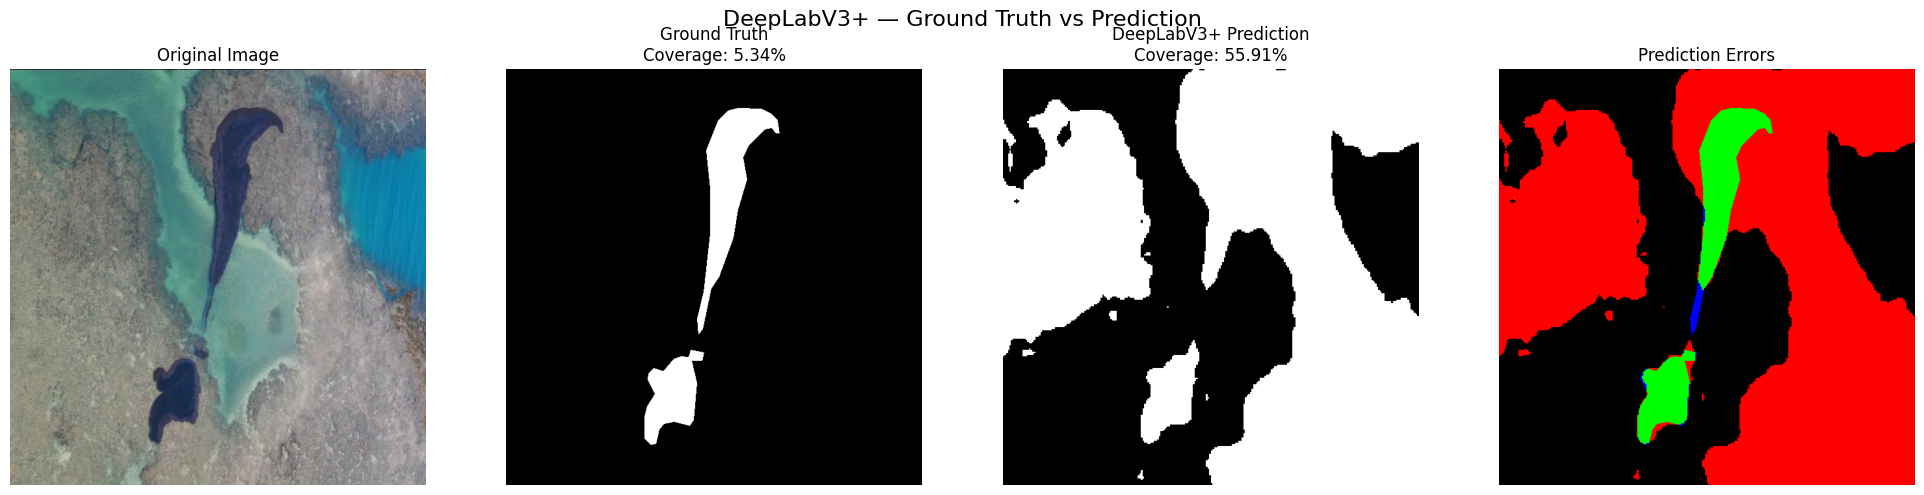

In [ ]:
# DeepLabV3+ — Ground Truth vs Prediction

gt_binary = np.isin(
    verified_gt,
    [1, 2, 4]
).astype(np.uint8)

pred_binary = deeplab_mask_original.astype(np.uint8)

# Error categories
tp_mask = (gt_binary == 1) & (pred_binary == 1)
fp_mask = (gt_binary == 0) & (pred_binary == 1)
fn_mask = (gt_binary == 1) & (pred_binary == 0)

# RGB error map
deeplab_error_map = np.zeros(
    (*gt_binary.shape, 3),
    dtype=np.uint8
)

# Green = True Positive
deeplab_error_map[tp_mask] = [0, 255, 0]

# Red = False Positive
deeplab_error_map[fp_mask] = [255, 0, 0]

# Blue = False Negative
deeplab_error_map[fn_mask] = [0, 0, 255]

plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 4, 2)
plt.imshow(gt_binary, cmap="gray")
plt.axis("off")
plt.title(
    f"Ground Truth\n"
    f"Coverage: {gt_coverage:.2f}%"
)

plt.subplot(1, 4, 3)
plt.imshow(pred_binary, cmap="gray")
plt.axis("off")
plt.title(
    f"DeepLabV3+ Prediction\n"
    f"Coverage: {deeplab_coverage:.2f}%"
)

plt.subplot(1, 4, 4)
plt.imshow(deeplab_error_map)
plt.axis("off")
plt.title("Prediction Errors")

plt.suptitle(
    "DeepLabV3+ — Ground Truth vs Prediction",
    fontsize=16
)

plt.tight_layout()
plt.show()

## U-Net training-set sanity check

U-Net loaded successfully.
Parameters: 1942577

Selected training images:
- 01_taylor_jpeg_jpg.rf.e15ac10b69ade00a5064bbcdf07d9492.jpg
- 037ff865416549-5af427762eb81_jpg.rf.2a6c1983a138a2cbb23242dcbdcf041f.jpg
- 037ff865416549-5af427762eb81_jpg.rf.2ac56a671ee3a28a7a674c201e557267.jpg
- 037ff865416549-5af427762eb81_jpg.rf.b39bf4dc6429237e9368e5f2dbc8286e.jpg
- 0517-ABIGSPILL-02-GULF-COAST-ENVIRONMENT-OIL-SPILL_jpg.rf.4f57dbbf1bfdc37dda6ba97ec22eae95.jpg


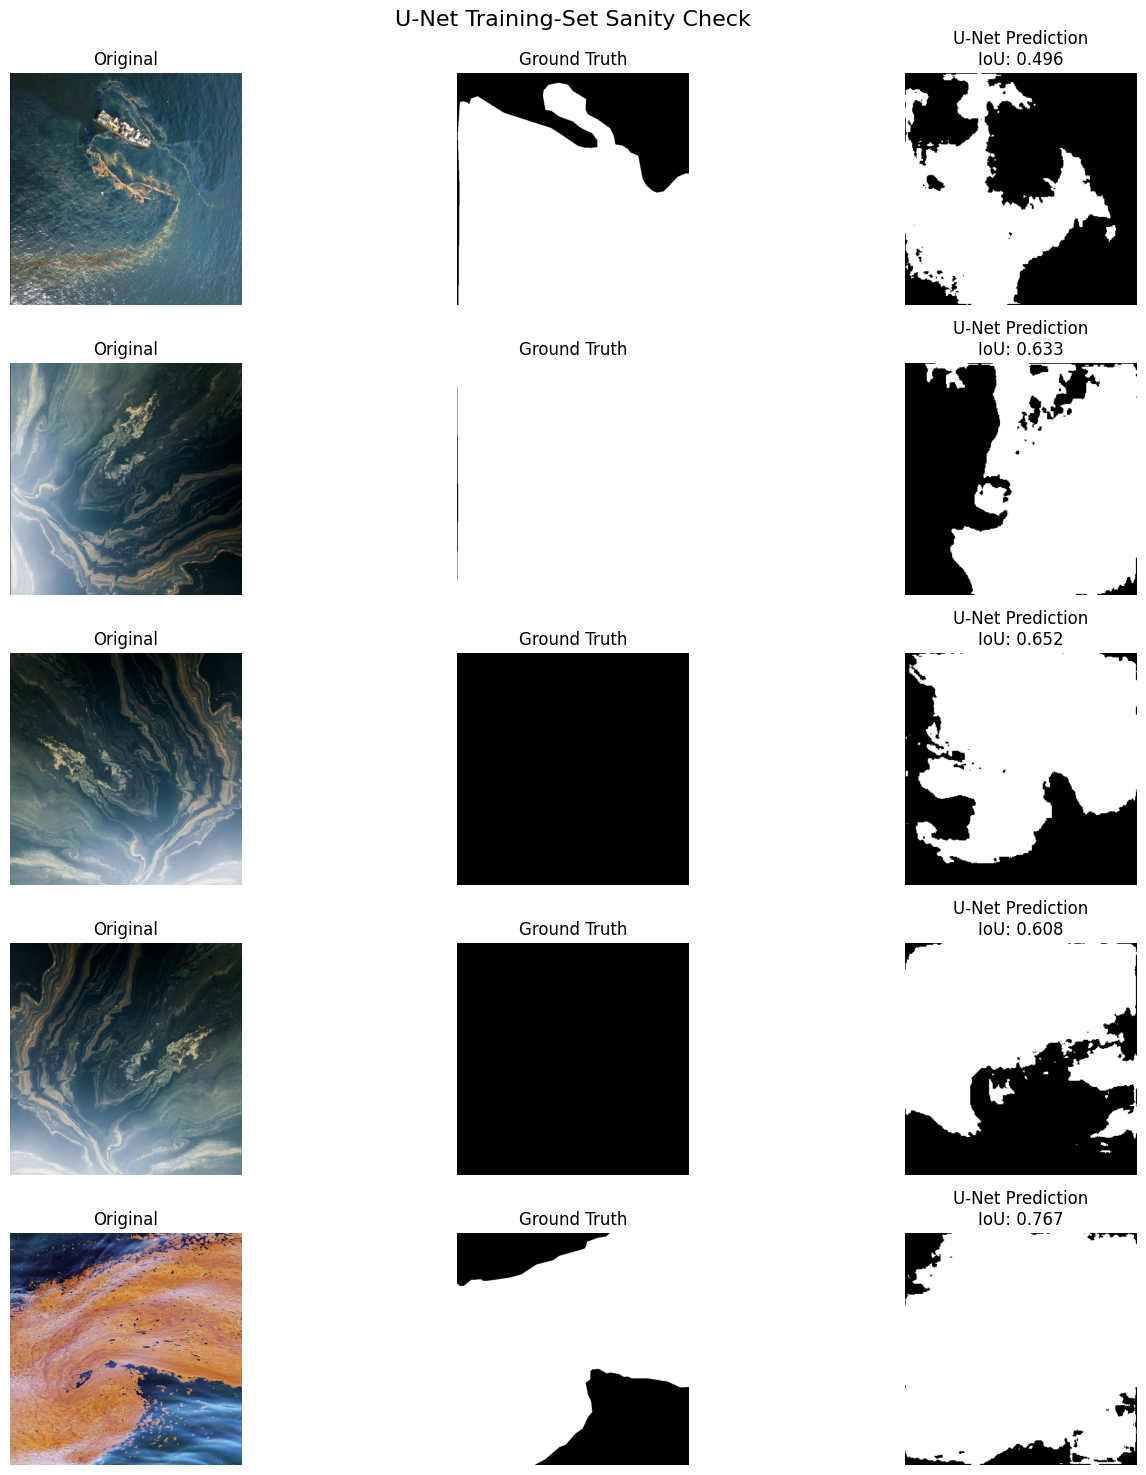

In [ ]:
# U-Net training-set sanity check
# 5 training images: Original | Ground Truth | Prediction

from pathlib import Path
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn.functional as F

from src.vision.unet import UNet

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT = (
    "/content/drive/MyDrive/PetroVision/"
    "models/cv_unet_001_best.pt"
)

TRAIN_DIR = Path("/content/PetroVision/data/lados/train")

# --------------------------------------------------
# Load U-Net
# --------------------------------------------------

unet = UNet(
    in_channels=3,
    out_channels=1
).to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

if "model_state_dict" in checkpoint:
    unet.load_state_dict(checkpoint["model_state_dict"])
else:
    unet.load_state_dict(checkpoint)

unet.eval()

print("U-Net loaded successfully.")
print("Parameters:", sum(p.numel() for p in unet.parameters()))

# --------------------------------------------------
# Select 5 training images
# --------------------------------------------------

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

train_images = sorted([
    p for p in TRAIN_DIR.iterdir()
    if p.suffix.lower() in image_extensions
    and not p.name.endswith("_mask.png")
])

selected_images = train_images[:5]

print("\nSelected training images:")
for p in selected_images:
    print("-", p.name)

# --------------------------------------------------
# Run predictions
# --------------------------------------------------

plt.figure(figsize=(15, 15))

for i, image_path_train in enumerate(selected_images):

    img = Image.open(image_path_train).convert("RGB")
    img_np = np.array(img)

    # Ground truth
    gt_path_train = image_path_train.with_name(
        image_path_train.stem + "_mask.png"
    )

    gt_mask = np.array(
        Image.open(gt_path_train).convert("L")
    )

    gt_binary = np.isin(
        gt_mask,
        [1, 2, 4]
    ).astype(np.uint8)

    # Prepare image
    tensor = torch.from_numpy(
        img_np.astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

    tensor = F.interpolate(
        tensor,
        size=(256, 256),
        mode="bilinear",
        align_corners=False
    )

    # Prediction
    with torch.no_grad():
        logits = unet(tensor)
        probability = torch.sigmoid(logits)
        prediction = (probability >= 0.5).float()

    pred_small = (
        prediction.squeeze()
        .cpu()
        .numpy()
        .astype(np.uint8)
    )

    pred_original = np.array(
        Image.fromarray(pred_small)
        .resize(
            img.size,
            resample=Image.Resampling.NEAREST
        )
    )

    # IoU for this training image
    intersection = np.logical_and(
        gt_binary == 1,
        pred_original == 1
    ).sum()

    union = np.logical_or(
        gt_binary == 1,
        pred_original == 1
    ).sum()

    image_iou = (
        intersection / union
        if union > 0 else 1.0
    )

    # Three-panel visualization
    base = (i * 3) + 1

    plt.subplot(5, 3, base)
    plt.imshow(img_np)
    plt.axis("off")
    plt.title("Original")

    plt.subplot(5, 3, base + 1)
    plt.imshow(gt_binary, cmap="gray")
    plt.axis("off")
    plt.title("Ground Truth")

    plt.subplot(5, 3, base + 2)
    plt.imshow(pred_original, cmap="gray")
    plt.axis("off")
    plt.title(f"U-Net Prediction\nIoU: {image_iou:.3f}")

plt.suptitle(
    "U-Net Training-Set Sanity Check",
    fontsize=16
)

plt.tight_layout()
plt.show()

Dataset sample:
Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Image range: 0.04313725605607033 0.9803921580314636
Mask unique values: [          0           1]
Petroleum pixels: 48548


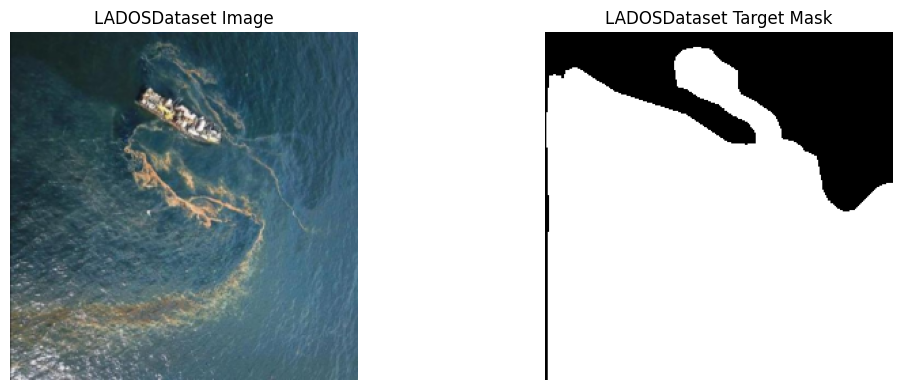

In [ ]:
# Verify one LADOS training sample and its target mask

from src.vision.lados_dataset import LADOSDataset
import matplotlib.pyplot as plt
import numpy as np

DATA_ROOT = Path("/content/PetroVision/data/lados")

train_dataset = LADOSDataset(
    root_dir=DATA_ROOT,
    split="train",
    image_size=256,
    augment=False
)

# First training sample
image_tensor, mask_tensor = train_dataset[0]

image_from_dataset = (
    image_tensor.permute(1, 2, 0).numpy()
)

mask_from_dataset = (
    mask_tensor.squeeze(0).numpy()
)

print("Dataset sample:")
print("Image shape:", image_tensor.shape)
print("Mask shape:", mask_tensor.shape)
print("Image range:", image_tensor.min().item(), image_tensor.max().item())
print("Mask unique values:", np.unique(mask_from_dataset))
print("Petroleum pixels:", int(mask_from_dataset.sum()))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_from_dataset)
plt.axis("off")
plt.title("LADOSDataset Image")

plt.subplot(1, 2, 2)
plt.imshow(mask_from_dataset, cmap="gray")
plt.axis("off")
plt.title("LADOSDataset Target Mask")

plt.tight_layout()
plt.show()

Exact training sample check
----------------------------
Target petroleum pixels    : 48,548
Predicted petroleum pixels : 32,173
IoU                        : 0.5827
Dice                       : 0.7363


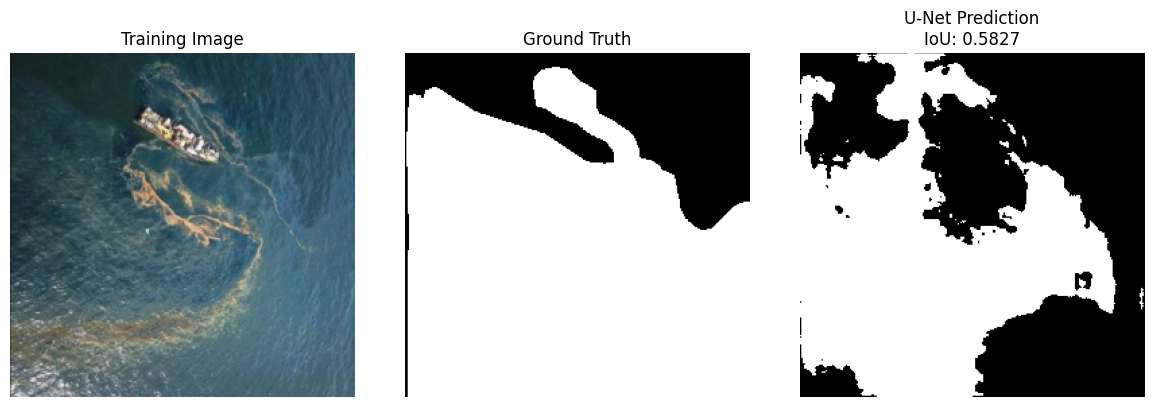

In [ ]:
# Exact LADOSDataset sample -> trained U-Net

import torch
import numpy as np
import matplotlib.pyplot as plt

# Use the exact sample already loaded
input_image = image_tensor.unsqueeze(0).to(DEVICE)
target_mask = mask_tensor.squeeze(0).numpy()

with torch.no_grad():
    logits = unet(input_image)
    probability = torch.sigmoid(logits)
    prediction = (probability >= 0.5).float()

pred_mask = prediction.squeeze().cpu().numpy().astype(np.uint8)

# Metrics
tp = ((target_mask == 1) & (pred_mask == 1)).sum()
fp = ((target_mask == 0) & (pred_mask == 1)).sum()
fn = ((target_mask == 1) & (pred_mask == 0)).sum()

iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0
dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0

print("Exact training sample check")
print("----------------------------")
print(f"Target petroleum pixels    : {int(target_mask.sum()):,}")
print(f"Predicted petroleum pixels : {int(pred_mask.sum()):,}")
print(f"IoU                        : {iou:.4f}")
print(f"Dice                       : {dice:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_from_dataset)
plt.axis("off")
plt.title("Training Image")

plt.subplot(1, 3, 2)
plt.imshow(target_mask, cmap="gray")
plt.axis("off")
plt.title("Ground Truth")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask, cmap="gray")
plt.axis("off")
plt.title(f"U-Net Prediction\nIoU: {iou:.4f}")

plt.tight_layout()
plt.show()

## Create the reusable DeepLab inference function

In [ ]:
# Reusable DeepLabV3+ inference function

import time
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image


def predict_deeplab(image, model, device, threshold=0.5):
    """
    Run DeepLabV3+ inference on a PIL RGB image.

    Returns:
        prediction_mask: binary mask at original image size
        coverage_percent: visible petroleum coverage in image space
        inference_time_ms: model inference time
        overlay: original image with predicted region highlighted
    """

    # Convert image to RGB
    image = image.convert("RGB")
    image_np = np.array(image)

    # Prepare tensor
    image_tensor = torch.from_numpy(
        image_np.astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0).to(device)

    # Same preprocessing used during training
    image_tensor = F.interpolate(
        image_tensor,
        size=(256, 256),
        mode="bilinear",
        align_corners=False
    )

    # Inference
    with torch.no_grad():

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        logits = model(image_tensor)

        if device.type == "cuda":
            torch.cuda.synchronize()

        inference_time_ms = (
            time.perf_counter() - start_time
        ) * 1000

    # Convert logits → probability → binary mask
    probability = torch.sigmoid(logits)

    prediction = (
        probability >= threshold
    ).float()

    prediction_small = (
        prediction.squeeze()
        .cpu()
        .numpy()
        .astype(np.uint8)
    )

    # Restore original image resolution
    prediction_mask = np.array(
        Image.fromarray(prediction_small)
        .resize(
            image.size,
            resample=Image.Resampling.NEAREST
        )
    )

    # Image-space visible coverage
    coverage_percent = (
        np.count_nonzero(prediction_mask)
        / prediction_mask.size
    ) * 100

    # Create overlay
    overlay = image_np.copy()

    mask_region = prediction_mask.astype(bool)

    overlay[mask_region] = (
        0.55 * overlay[mask_region]
        + 0.45 * np.array([255, 0, 0])
    ).astype(np.uint8)

    return (
        prediction_mask,
        float(coverage_percent),
        float(inference_time_ms),
        overlay
    )


print("DeepLabV3+ inference function created successfully.")

DeepLabV3+ inference function created successfully.


## Test the reusable DeepLab function

DeepLabV3+ reusable inference test
-----------------------------------
Image size: (640, 640)
Coverage: 55.91%
Inference time: 18.04 ms


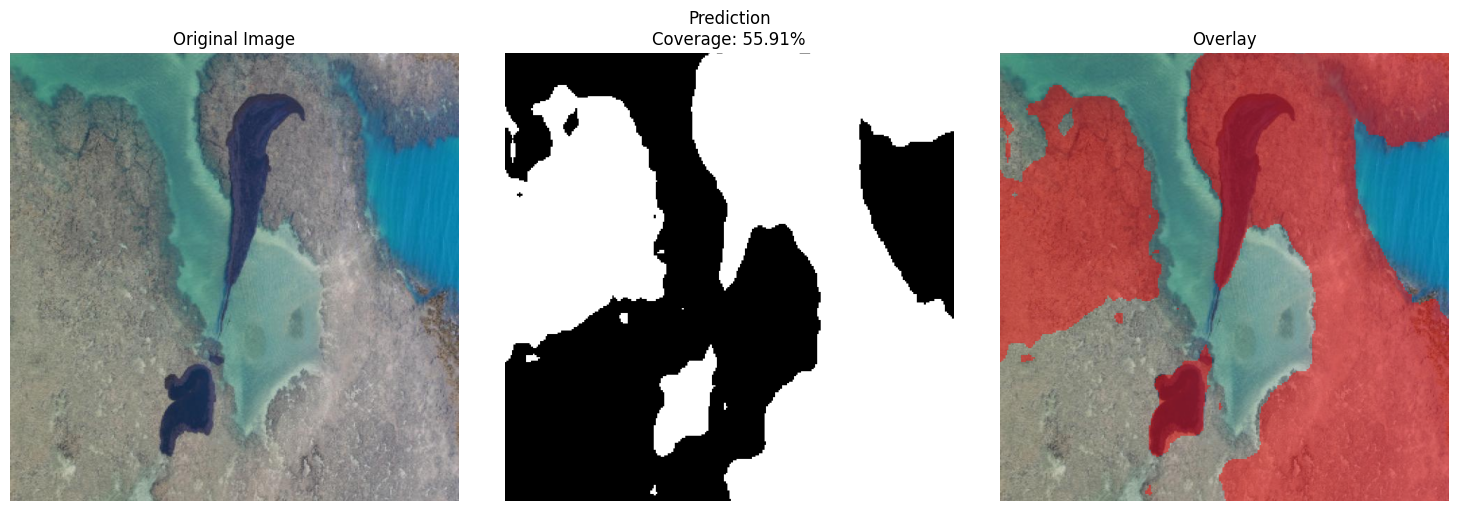

In [ ]:
# Test reusable DeepLabV3+ inference function

test_image = Image.open(
    "/content/PetroVision/data/lados/test/"
    "1-s2-0-S0025326X20300795-ga1_jpg.rf."
    "146acb49222beff322771e6a18d1c5ee.jpg"
).convert("RGB")

(
    test_mask,
    test_coverage,
    test_time,
    test_overlay
) = predict_deeplab(
    test_image,
    model,
    device,
    threshold=0.5
)

print("DeepLabV3+ reusable inference test")
print("-----------------------------------")
print(f"Image size: {test_image.size}")
print(f"Coverage: {test_coverage:.2f}%")
print(f"Inference time: {test_time:.2f} ms")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(test_image)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 3, 2)
plt.imshow(test_mask, cmap="gray")
plt.axis("off")
plt.title(f"Prediction\nCoverage: {test_coverage:.2f}%")

plt.subplot(1, 3, 3)
plt.imshow(test_overlay)
plt.axis("off")
plt.title("Overlay")

plt.tight_layout()
plt.show()

In [ ]:
# Diagnose DeepLab probability distribution

with torch.no_grad():
    image_tensor = torch.from_numpy(
        np.array(test_image).astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0).to(device)

    image_tensor = F.interpolate(
        image_tensor,
        size=(256, 256),
        mode="bilinear",
        align_corners=False
    )

    logits = model(image_tensor)
    probabilities = torch.sigmoid(logits).squeeze().cpu().numpy()

print("Probability statistics")
print("----------------------")
print(f"Min:    {probabilities.min():.4f}")
print(f"Mean:   {probabilities.mean():.4f}")
print(f"Median: {np.median(probabilities):.4f}")
print(f"Max:    {probabilities.max():.4f}")

print("\nCoverage at different thresholds")
print("---------------------------------")

for threshold in [0.1, 0.3, 0.5, 0.7, 0.9, 0.95]:
    coverage = (
        np.mean(probabilities >= threshold) * 100
    )
    print(f"Threshold {threshold:.2f}: {coverage:.2f}%")

Probability statistics
----------------------
Min:    0.0004
Mean:   0.5344
Median: 0.6797
Max:    1.0000

Coverage at different thresholds
---------------------------------
Threshold 0.10: 68.40%
Threshold 0.30: 61.16%
Threshold 0.50: 55.91%
Threshold 0.70: 49.15%
Threshold 0.90: 32.84%
Threshold 0.95: 22.27%


New test image
----------------
Image: Oil-Pollution_original_oil-17-jpg_0e4224e4-4599-4241-85d3-fc44ce1bdb2f_jpg.rf.65f8cf704e1fa0d3697b75a9512fd406.jpg
Ground-truth petroleum coverage: 96.68%


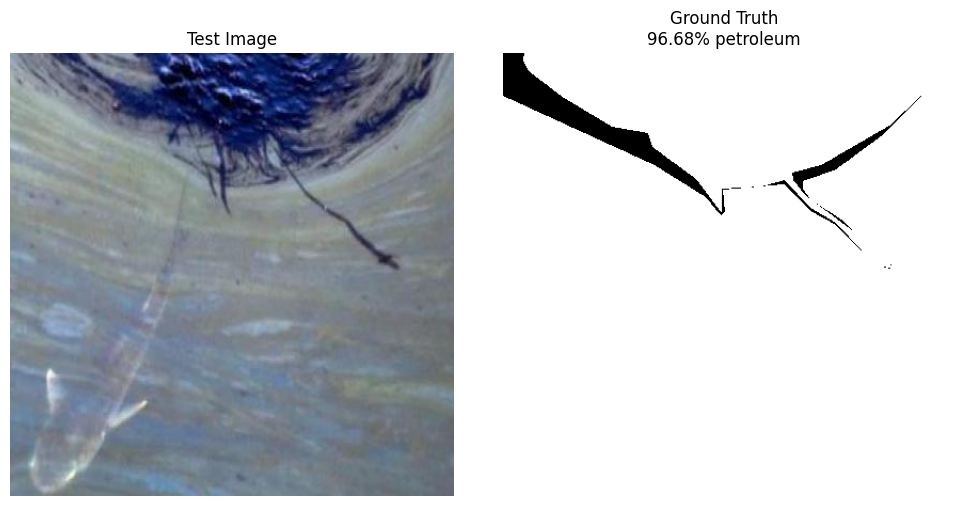

In [ ]:
# Select a different LADOS test image with petroleum in the ground truth

import random
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

TEST_DIR = Path("/content/PetroVision/data/lados/test")

candidates = []

for mask_path in TEST_DIR.glob("*_mask.png"):
    mask = np.array(Image.open(mask_path))

    # LADOS petroleum IDs: Emulsion=1, Oil=2, Sheen=4
    petroleum_pixels = np.isin(mask, [1, 2, 4]).sum()

    if petroleum_pixels > 0:
        candidates.append((mask_path, petroleum_pixels))

# Choose a different image from the available test images
mask_path, petroleum_pixels = random.choice(candidates)

image_path = mask_path.with_name(
    mask_path.name.replace("_mask.png", ".jpg")
)

test_image_2 = Image.open(image_path).convert("RGB")

gt_mask_2 = np.array(Image.open(mask_path))
gt_petroleum_2 = np.isin(gt_mask_2, [1, 2, 4])

gt_coverage_2 = gt_petroleum_2.mean() * 100

print("New test image")
print("----------------")
print("Image:", image_path.name)
print(f"Ground-truth petroleum coverage: {gt_coverage_2:.2f}%")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(test_image_2)
plt.axis("off")
plt.title("Test Image")

plt.subplot(1, 2, 2)
plt.imshow(gt_petroleum_2, cmap="gray")
plt.axis("off")
plt.title(f"Ground Truth\n{gt_coverage_2:.2f}% petroleum")

plt.tight_layout()
plt.show()

DeepLabV3+ — New Test Image
----------------------------
Image: Oil-Pollution_original_oil-17-jpg_0e4224e4-4599-4241-85d3-fc44ce1bdb2f_jpg.rf.65f8cf704e1fa0d3697b75a9512fd406.jpg
Ground-truth coverage: 96.68%
Predicted coverage:    28.61%
Inference time:        19.49 ms


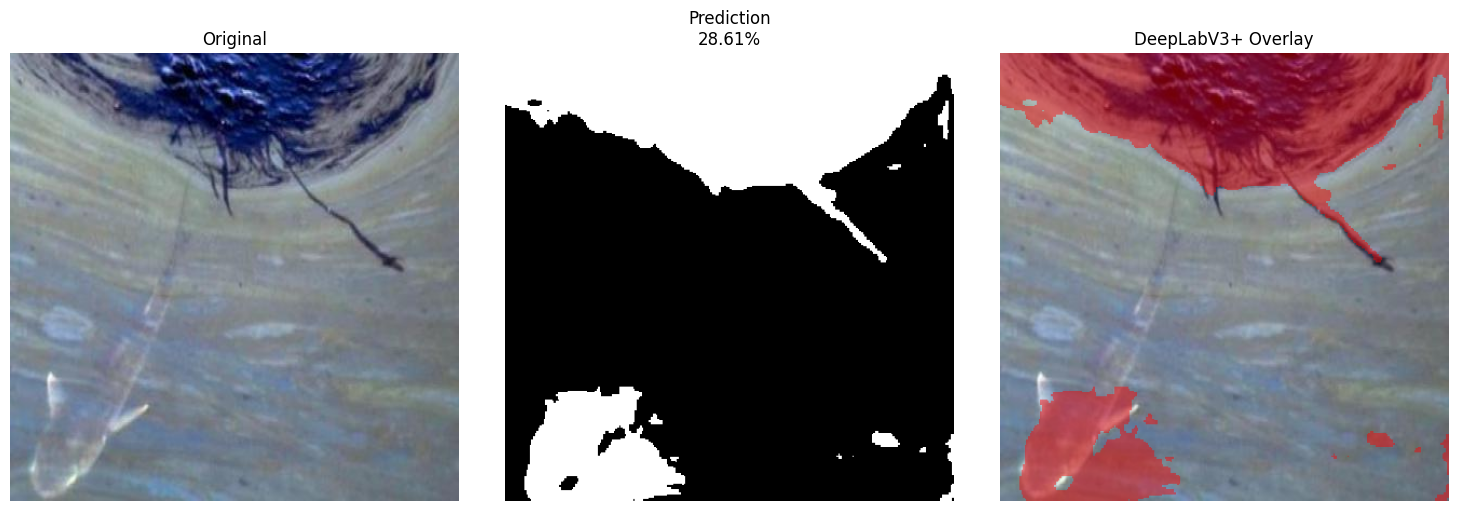

In [ ]:
# DeepLabV3+ inference on the new test image

(
    prediction_mask_2,
    coverage_2,
    inference_time_2,
    overlay_2
) = predict_deeplab(
    test_image_2,
    model,
    device,
    threshold=0.5
)

print("DeepLabV3+ — New Test Image")
print("----------------------------")
print(f"Image: {image_path.name}")
print(f"Ground-truth coverage: {gt_coverage_2:.2f}%")
print(f"Predicted coverage:    {coverage_2:.2f}%")
print(f"Inference time:        {inference_time_2:.2f} ms")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(test_image_2)
plt.axis("off")
plt.title("Original")

plt.subplot(1, 3, 2)
plt.imshow(prediction_mask_2, cmap="gray")
plt.axis("off")
plt.title(f"Prediction\n{coverage_2:.2f}%")

plt.subplot(1, 3, 3)
plt.imshow(overlay_2)
plt.axis("off")
plt.title("DeepLabV3+ Overlay")

plt.tight_layout()
plt.show()